X shape: torch.Size([100, 2])  Y shape: torch.Size([100, 1])


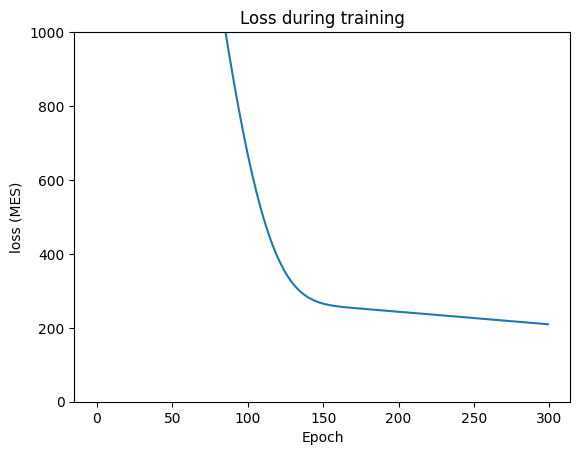

In [4]:
import pandas as pd 
import torch as torch
from torch import nn
import matplotlib.pyplot as plt
students = pd.read_csv("students_100.csv")

X = torch.tensor(
    students[["study_hours","phone_hours"]].values,
    dtype = torch.float32
)

Y = torch.tensor(
    students[["maths"]].values,
    dtype=torch.float32
)
print("X shape:",X.shape," Y shape:",Y.shape)
torch.manual_seed(42)
model = nn.Sequential(
    nn.Linear(2,3),
    nn.ReLU(),
    nn.Linear(3,1),
)
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(),lr=0.01)
losses = []
for epoch in range(300):
    guess = model(X)
    loss = loss_fn(guess,Y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
if epoch % 50 == 0:
    print(f"epoch {epoch:3}: loss = {loss.item():.1f}")

plt.plot(losses)
plt.ylim(0,1000)
plt.title("Loss during training")
plt.xlabel("Epoch")
plt.ylabel("loss (MES)")
plt.show()